# Destilación paramétrica SW-UDE — v5.1 · familias COVID

Este notebook ejecuta `experimento_destilacion_parametrica_v5_1_familias_covid.jl`.

Características principales:

- condiciones iniciales consistentes con el manuscrito;
- modelo SIR **discreto**, Euler explícito con \(\Delta t=1\) día;
- no utiliza `Tsit5`;
- ajuste algebraico de \(\beta_{\mathrm{SW-UDE}}\) usando \(I_{\mathrm{SW-UDE}}/N\);
- reconstrucción dinámica comparada contra \(I_{\mathrm{observado}}\);
- selección exclusivamente con TRAIN;
- TEST se usa únicamente para evaluación final;
- M1 y M2 son los modelos principales;
- C1, C11 y C12 son controles/análisis de sensibilidad;
- se exportan automáticamente las 10 soluciones dinámicas de cada familia.

**Recomendación:** iniciar este notebook con un kernel Julia limpio para evitar redefiniciones de constantes.


### Familias adicionales orientadas a COVID-19

Además de las familias ya existentes, la versión v5 incorpora:

\[
\mathrm{C7}:
\qquad
\beta(t,I)
=
\frac{\beta_0+b t}
{1+\kappa (I/N)^h}
\]

como feedback no lineal tipo Hill;

\[
\mathrm{C8}:
\qquad
\beta(t,I)
=
\beta_0+b t
-
\Delta
\frac{(I/N)^h}
{K^h+(I/N)^h}
\]

como respuesta saturante;

\[
\mathrm{C9}:
\qquad
\beta(t,I)
=
\beta_0+b t
-\Delta_1\sigma[k_1(t-t_1)]
+\Delta_2\sigma[k_2(t-t_2)]
-w_2 I/N
\]

como intervención seguida de relajación;

\[
\mathrm{C13}:
\qquad
\beta(t,I)
=
\beta_0+b t
+
A\sin\left(\frac{2\pi t}{365}+\phi\right)
-w_2 I/N
\]

como control de estacionalidad anual fija; y

\[
\mathrm{C15}:
\qquad
\beta(t,I)
=
\exp\left[
\eta_0+\eta_1t
+A\sin(\omega t+\phi)
-\kappa I/N
\right]
\]

como modelo multiplicativo con positividad estructural.

Todas estas familias se ejecutan como sensibilidad y **no modifican la regla de selección principal M1 vs. M2**.


In [1]:
using CSV
using DataFrames
using LinearAlgebra
using Base.Threads

println("Julia version       : ", VERSION)
println("Threads Julia       : ", Threads.nthreads())
println("CPU threads sistema : ", Sys.CPU_THREADS)
println("BLAS threads antes  : ", BLAS.get_num_threads())

if Threads.nthreads() == 1
    @warn "El kernel Julia tiene un solo thread. El experimento funcionará, pero los multistarts no se paralelizarán."
end


Julia version       : 1.10.5
Threads Julia       : 32
CPU threads sistema : 32
BLAS threads antes  : 1


## 1. Directorio de trabajo

El CSV y el archivo `.jl` deben estar en `OUTDIR`.


In [2]:
OUTDIR = pwd()

ARCHIVO_DATOS = joinpath(
    OUTDIR,
    "datos_reales_curvas.csv"
)

ARCHIVO_JULIA = joinpath(
    OUTDIR,
    "experimento_destilacion_parametrica_v5_1_familias_covid.jl"
)

@assert isfile(ARCHIVO_DATOS) "No existe: $(ARCHIVO_DATOS)"
@assert isfile(ARCHIVO_JULIA) "No existe: $(ARCHIVO_JULIA)"

println("OUTDIR       = ", OUTDIR)
println("CSV          = ", ARCHIVO_DATOS)
println("Código Julia = ", ARCHIVO_JULIA)


OUTDIR       = /home/tesis/codigos/SW_UDE/notebook/regresion_variantes_v5_1_corregido
CSV          = /home/tesis/codigos/SW_UDE/notebook/regresion_variantes_v5_1_corregido/datos_reales_curvas.csv
Código Julia = /home/tesis/codigos/SW_UDE/notebook/regresion_variantes_v5_1_corregido/experimento_destilacion_parametrica_v5_1_familias_covid.jl


## 2. Condiciones iniciales del manuscrito

Se utiliza:

\[
N=19\,660\,000,\qquad
S_0=19\,348\,776,\qquad
I_0=26\,390,\qquad
R_0=284\,834.
\]

El script detendrá la ejecución si estos valores no coinciden.


In [3]:
N_REF = 19_660_000.0
GAMMA = 1 / 7

S0 = 19_348_776.0
I0 =     26_390.0
R0 =    284_834.0

U0_SIR = Float64[
    S0,
    I0,
    R0
]

@assert sum(U0_SIR) == N_REF

println("N      = ", N_REF)
println("gamma  = ", GAMMA)
println("U0     = ", U0_SIR)
println("S+I+R  = ", sum(U0_SIR))


N      = 1.966e7
gamma  = 0.14285714285714285
U0     = [1.9348776e7, 26390.0, 284834.0]
S+I+R  = 1.966e7


## 3. Inspección previa de los datos


In [4]:
df_check = CSV.read(
    ARCHIVO_DATOS,
    DataFrame
)

columnas = [
    :dia,
    :es_test,
    :I_observado,
    :I_UDE,
    :I_Windowed,
    :beta_UDE,
    :beta_Windowed
]

for c in columnas
    @assert c in propertynames(df_check) "Falta la columna $(c)"
end

println("Filas: ", nrow(df_check))
println()

for c in columnas
    println(
        rpad(string(c), 18),
        " missing = ",
        count(ismissing, df_check[!, c])
    )
end

println()
println(
    "Primer I observado = ",
    df_check.I_observado[1]
)


Filas: 206

dia                missing = 0
es_test            missing = 0
I_observado        missing = 0
I_UDE              missing = 0
I_Windowed         missing = 0
beta_UDE           missing = 1
beta_Windowed      missing = 1

Primer I observado = 26390.0


## 4. Partición temporal


In [5]:
es_test_check = Bool.(df_check.es_test)

idx_train_check = findall(.!es_test_check)
idx_test_check  = findall(es_test_check)

println(
    "TRAIN: n = ",
    length(idx_train_check),
    " | días ",
    df_check.dia[first(idx_train_check)],
    "–",
    df_check.dia[last(idx_train_check)]
)

println(
    "TEST : n = ",
    length(idx_test_check),
    " | días ",
    df_check.dia[first(idx_test_check)],
    "–",
    df_check.dia[last(idx_test_check)]
)


TRAIN: n = 165 | días 0.0–164.0
TEST : n = 41 | días 165.0–205.0


## 5. Ejecutar el experimento

Esta celda realiza los 50 multistarts algebraicos y los 10 refinamientos dinámicos por familia usando `Threads.@threads`.


CONFIGURACIÓN
Integrador       : Euler discreto
Δt               : 1.0 día
Threads Julia    : 32
Threads CPU      : 32
Threads BLAS     : 1
Multistarts alg. : 50
Refinam. dinám.  : 10
lambda_beta      : 0.5
lambda_I         : 0.5
Grupos activos   : [:principal, :control, :extendida, :covid]
Salida           : /home/tesis/codigos/SW_UDE/notebook/regresion_variantes_v5_1_corregido/destilacion_parametrica_v5_1_covid

CONDICIONES INICIALES
S0            =     19348776.00   (manuscrito     19348776.00)
I0            =        26390.00   (manuscrito        26390.00)
R0            =       284834.00   (manuscrito       284834.00)
S0+I0+R0      =     19660000.00   N_REF =     19660000.00
Condiciones iniciales consistentes con el manuscrito ✓

Partición tomada de la columna es_test.
Malla temporal uniforme con Δt = 1.0 ✓
N = 206 | train = 165 (t = 0.0–164.0) | test = 41 (t = 165.0–205.0)

LÍNEAS BASE DE PERSISTENCIA
I(t) ≡ I(164) = 16584 | RMSE = 12966.7 | MAE = 10719.1 | R² = -2.1583
β(t) ≡ β(16

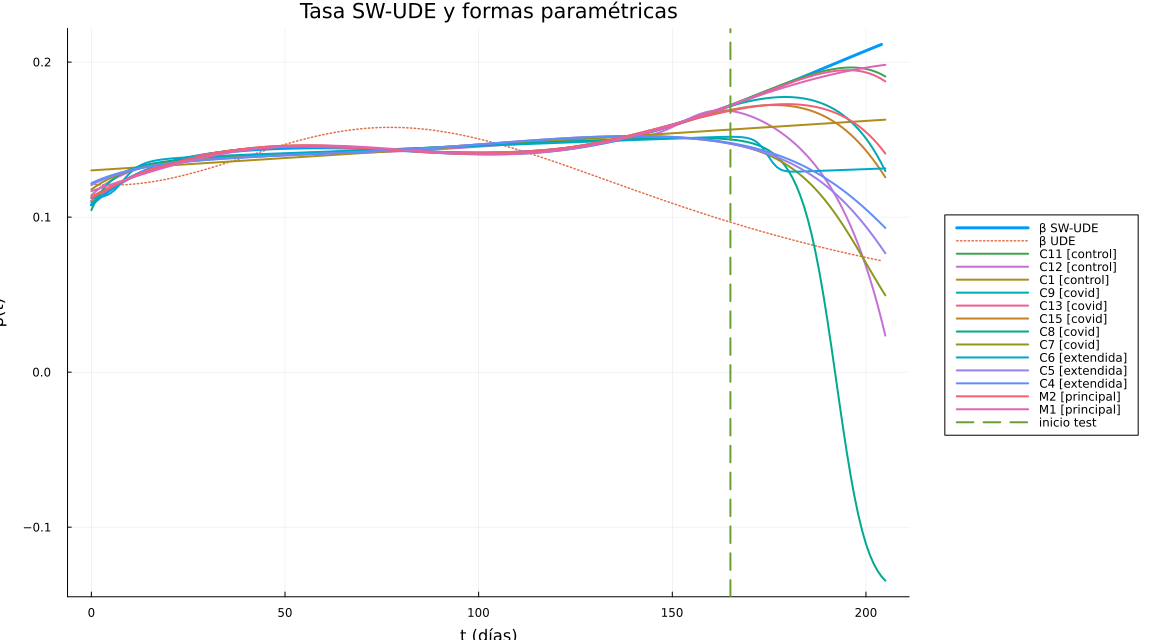

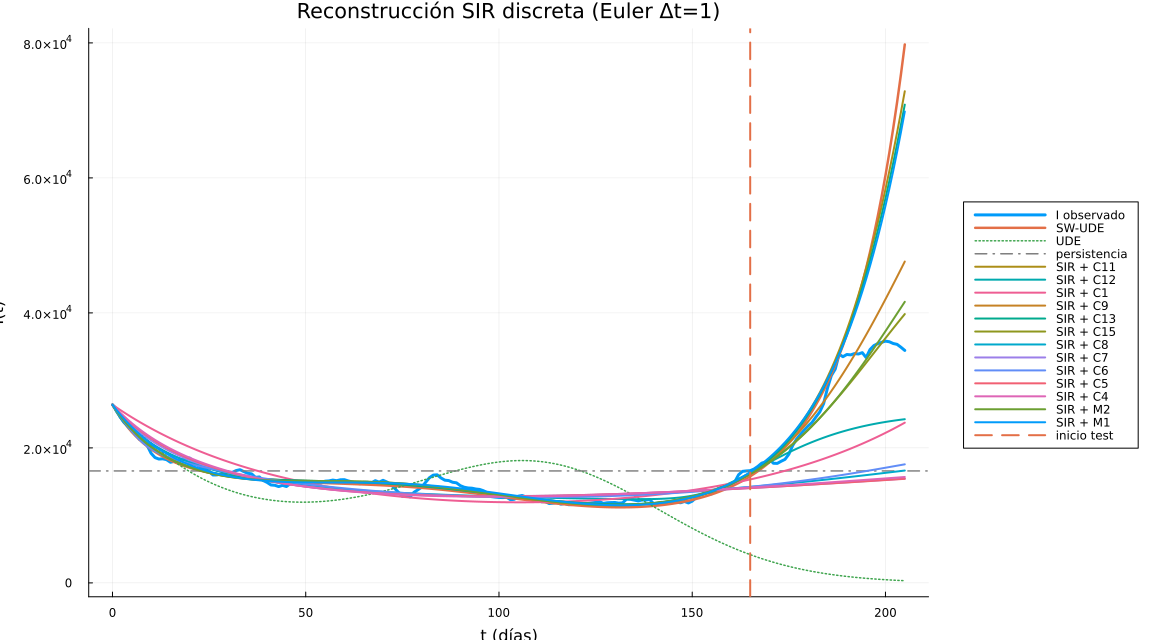

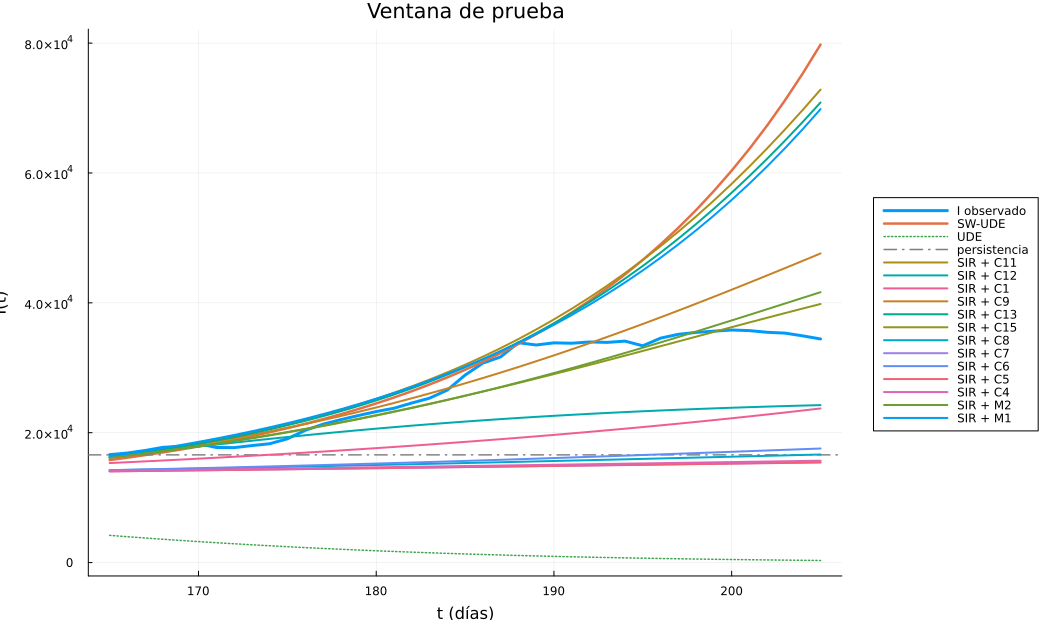


MODELO PRINCIPAL SELECCIONADO
(sólo M1/M2; exclusivamente con TRAIN)
M2: M1 − w₂·(I/N)
parámetros: β₀=0.13141007, b=0.00028855135, A=0.013224391, ω=0.038312106, φ=0.11318862, w₂=15.451891
ecuación: beta(t,I) = 0.131410072783 +0.000288551348*t + 0.013224391245*sin(0.038312105532*t +0.113188615927) - 15.451890751182*(I/N)

TRAIN  L = 0.02726403 | RMSE β = 0.00109815 | RMSE I = 606.7 | válido = true

EVALUACIÓN FINAL EN TEST (no usada para ajustar, validar ni seleccionar):
  β SW-UDE | R² =  -5.7394 | RMSE = 0.03060559 | RMSE/persistencia = 1.298
  I(t)      | R² =  +0.8577 | RMSE =     2752.1 | MAE =     1958.6 | RMSE/persistencia = 0.212
  validez TEST = true

Controles/sensibilidad:
  C11  | L_train=0.022836 | RMSE_I_test=   13357.4 | coc_pers=1.030 | válido_test=true
  C12  | L_train=0.098688 | RMSE_I_test=    7915.8 | coc_pers=0.610 | válido_test=true
  C1   | L_train=0.335532 | RMSE_I_test=    9795.6 | coc_pers=0.755 | válido_test=true

Salidas en: /home/tesis/codigos/SW_UDE/notebo

In [6]:
@time include(ARCHIVO_JULIA)


## 6. Resumen de familias


In [7]:
display(
    select(
        resultados,
        :clave,
        :grupo,
        :k,
        :loss_conjunta_train,
        :rmse_beta_train,
        :rmse_beta_test,
        :r2_beta_test,
        :coc_beta_pers,
        :rmse_I_train,
        :rmse_I_test,
        :mae_I_test,
        :r2_I_test,
        :coc_I_pers,
        :valido_train,
        :valido_test
    )
)


Row,clave,grupo,k,loss_conjunta_train,rmse_beta_train,rmse_beta_test,r2_beta_test,coc_beta_pers,rmse_I_train,rmse_I_test,mae_I_test,r2_I_test,coc_I_pers,valido_train,valido_test
,String,String,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Bool,Bool
1,C11,control,6,0.0228358,0.000654742,0.00634708,0.710155,0.269258,592.372,13357.4,8128.8,-2.35145,1.03013,true,true
2,C12,control,5,0.098688,0.00341578,0.0809865,-46.1893,3.43564,893.158,7915.81,6263.27,-0.177005,0.610472,true,true
3,C1,control,2,0.335532,0.00645874,0.0333221,-6.98882,1.4136,1600.74,9795.62,8390.05,-0.8024,0.755443,true,true
4,C9,covid,9,0.0229576,0.000662773,0.0315624,-6.16732,1.33895,593.437,4185.22,2685.76,0.670978,0.322767,true,true
5,C13,covid,5,0.0229745,0.000669428,0.00757207,0.587478,0.321225,593.129,12568.1,7543.04,-1.96707,0.96926,true,true
6,C15,covid,6,0.0282434,0.00117595,0.0369284,-8.81156,1.56659,609.556,2515.92,1825.63,0.8811,0.194029,true,true
7,C8,covid,5,0.212,0.00570716,0.177976,-226.899,7.55019,1078.84,13647.1,11938.7,-2.49838,1.05247,true,false
8,C7,covid,4,0.264052,0.00642838,0.0862172,-52.4818,3.65754,1180.83,14341.3,12573.6,-2.86337,1.10601,true,true
9,C6,extendida,5,0.18528,0.00535758,0.0591104,-24.1389,2.50761,999.912,13194.6,11560.9,-2.27024,1.01757,true,true


## 7. Comparación de la trayectoria \(I(t)\)


In [8]:
display(comparacion_I)


Row,modelo,tipo,rmse_train,mae_train,r2_train,rmse_test,mae_test,r2_test,coc_persistencia,valido_test
,String,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Bool
1,SIR + C15,covid,609.556,452.438,0.955341,2515.92,1825.63,0.8811,0.194029,true
2,SIR + M2,principal,606.729,450.469,0.955754,2752.06,1958.6,0.857733,0.21224,true
3,SIR + C9,covid,593.437,435.966,0.957671,4185.22,2685.76,0.670978,0.322767,true
4,SIR + C12,control,893.158,697.504,0.904117,7915.81,6263.27,-0.177005,0.610472,true
5,SIR + C1,control,1600.74,1284.1,0.692017,9795.62,8390.05,-0.8024,0.755443,true
6,SIR + M1,principal,616.219,458.838,0.954359,12053.5,7303.38,-1.72905,0.929571,true
7,SIR + C13,covid,593.129,436.642,0.957715,12568.1,7543.04,-1.96707,0.96926,true
8,Persistencia,baseline,NaN,NaN,NaN,12966.7,10719.1,-2.15826,1.0,true
9,SIR + C6,extendida,999.912,797.355,0.879826,13194.6,11560.9,-2.27024,1.01757,true


## 8. Modelo principal seleccionado

La selección se realiza únicamente entre M1 y M2, usando la pérdida conjunta de TRAIN.


In [9]:
display(
    DataFrame(
        clave = [mejor.clave],
        forma = [mejor.forma],
        parametros = [mejor.parametros],
        loss_train = [mejor.loss_conjunta_train],
        rmse_beta_test = [mejor.rmse_beta_test],
        r2_beta_test = [mejor.r2_beta_test],
        rmse_I_test = [mejor.rmse_I_test],
        mae_I_test = [mejor.mae_I_test],
        r2_I_test = [mejor.r2_I_test],
        coc_I_persistencia = [mejor.coc_I_pers],
        valido_test = [mejor.valido_test]
    )
)


Row,clave,forma,parametros,loss_train,rmse_beta_test,r2_beta_test,rmse_I_test,mae_I_test,r2_I_test,coc_I_persistencia,valido_test
,String,String,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Bool
1,M2,M1 − w₂·(I/N),"β₀=0.13141007, b=0.00028855135, A=0.013224391, ω=0.038312106, φ=0.11318862, w₂=15.451891",0.027264,0.0306056,-5.73937,2752.06,1958.6,0.857733,0.21224,true


## 9. Top 10 dinámico de M1


In [10]:
if haskey(top10_dinamicos, "M1")
    display(
        select(
            top10_dinamicos["M1"],
            :ranking_dinamico,
            :loss_conjunta_train,
            :parametros,
            :periodo_dias,
            :rmse_beta_train,
            :rmse_beta_test,
            :r2_beta_test,
            :rmse_I_train,
            :rmse_I_test,
            :mae_I_test,
            :r2_I_test,
            :coc_I_pers,
            :valido_train,
            :valido_test
        )
    )
end


Row,ranking_dinamico,loss_conjunta_train,parametros,periodo_dias,rmse_beta_train,rmse_beta_test,r2_beta_test,rmse_I_train,rmse_I_test,mae_I_test,r2_I_test,coc_I_pers,valido_train,valido_test
,Int64,Float64,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Bool,Bool
1,1,0.0333695,"β₀=0.116294618675, b=0.000333377988068, A=0.0136063721579, ω=0.0383121119833, φ=0.0318556829083",164.0,0.00156308,0.00620992,0.722547,616.219,12053.5,7303.38,-1.72905,0.929571,true,true
2,2,0.0333707,"β₀=0.116297604101, b=0.0003333431267, A=0.013606641772, ω=0.0383121055425, φ=0.0320570698081",164.0,0.00156311,0.00621187,0.722372,616.23,12051.8,7302.32,-1.72829,0.92944,true,true
3,3,0.033501,"β₀=0.116558935222, b=0.000330203981347, A=0.0134690290088, ω=0.0385123794386, φ=0.0158037984666",163.147,0.00157168,0.0064921,0.696758,616.404,11856.0,7187.04,-1.64037,0.914343,true,true
4,4,0.0335076,"β₀=0.116571456627, b=0.000330051801313, A=0.0134625258291, ω=0.0385227119844, φ=0.0147150576501",163.103,0.00157215,0.00650645,0.695416,616.406,11844.1,7179.35,-1.63505,0.91342,true,true
5,5,0.0335081,"β₀=0.116571393032, b=0.000330039711158, A=0.0134630423804, ω=0.0385210568328, φ=0.0150090203303",163.11,0.00157192,0.00650797,0.695274,616.455,11836.7,7172.9,-1.63176,0.912851,true,true
6,6,0.0335145,"β₀=0.116584329927, b=0.000329889500879, A=0.0134582297451, ω=0.0385318758905, φ=0.0141935223088",163.065,0.00157238,0.00651941,0.694202,616.456,11832.1,7171.32,-1.62974,0.9125,true,true
7,7,0.0335202,"β₀=0.116593686077, b=0.000329759770831, A=0.0134535541943, ω=0.0385393793343, φ=0.0135469690294",163.033,0.00157249,0.00653195,0.693024,616.514,11815.3,7158.63,-1.62225,0.911199,true,true
8,8,0.0335206,"β₀=0.116595120841, b=0.000329749759398, A=0.01345164601, ω=0.0385397468015, φ=0.013451794082",163.031,0.00157265,0.00653371,0.692859,616.488,11816.4,7160.13,-1.62275,0.911286,true,true
9,9,0.0335381,"β₀=0.116628333069, b=0.000329346338562, A=0.0134365230774, ω=0.0385689305449, φ=0.0112219072298",162.908,0.00157366,0.00656725,0.689698,616.537,11794.7,7147.71,-1.61312,0.909612,true,true


## 10. Top 10 dinámico de M2


In [11]:
if haskey(top10_dinamicos, "M2")
    display(
        select(
            top10_dinamicos["M2"],
            :ranking_dinamico,
            :loss_conjunta_train,
            :parametros,
            :periodo_dias,
            :rmse_beta_train,
            :rmse_beta_test,
            :r2_beta_test,
            :rmse_I_train,
            :rmse_I_test,
            :mae_I_test,
            :r2_I_test,
            :coc_I_pers,
            :valido_train,
            :valido_test
        )
    )
end


Row,ranking_dinamico,loss_conjunta_train,parametros,periodo_dias,rmse_beta_train,rmse_beta_test,r2_beta_test,rmse_I_train,rmse_I_test,mae_I_test,r2_I_test,coc_I_pers,valido_train,valido_test
,Int64,Float64,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Bool,Bool
1,1,0.027264,"β₀=0.131410072783, b=0.000288551347911, A=0.0132243912446, ω=0.0383121055316, φ=0.113188615927, w₂=15.4518907512",164.0,0.00109815,0.0306056,-5.73937,606.729,2752.06,1958.6,0.857733,0.21224,true,true
2,2,0.0272673,"β₀=0.131392100996, b=0.000288282966, A=0.0131917297317, ω=0.0383121055317, φ=0.112927341609, w₂=15.3942021555",164.0,0.00110225,0.0305746,-5.72575,606.23,2753.25,1960.22,0.857611,0.212332,true,true
3,3,0.027268,"β₀=0.131410366348, b=0.000288344199989, A=0.013193906058, ω=0.0383121055326, φ=0.112409222234, w₂=15.4291757429",164.0,0.00110116,0.0306179,-5.74479,606.384,2751.55,1960.05,0.857787,0.212201,true,true
4,4,0.027278,"β₀=0.131465586238, b=0.000287763255009, A=0.0131728143695, ω=0.0383121055331, φ=0.113075634688, w₂=15.4412087007",164.0,0.00110355,0.0306991,-5.78063,606.204,2750.15,1965.37,0.857931,0.212093,true,true
5,5,0.0272797,"β₀=0.131481240284, b=0.000287688506149, A=0.0131709368113, ω=0.0383121055316, φ=0.113155304948, w₂=15.4551450272",164.0,0.00110352,0.0307259,-5.79248,606.232,2749.39,1965.92,0.85801,0.212034,true,true
6,6,0.176603,"β₀=0.163234445303, b=4.51614127455e-05, A=0.00578321579222, ω=0.0710915824958, φ=3.14159265359, w₂=31.9162933324",88.3816,0.00533348,0.0882317,-55.0103,934.569,15085.7,13007.3,-3.2748,1.16341,true,true
7,7,0.176603,"β₀=0.163250308938, b=4.51190891119e-05, A=0.00578431035505, ω=0.0710905406595, φ=3.14159265359, w₂=31.9329901617",88.3829,0.00533357,0.0882576,-55.0432,934.536,15086.7,13008.2,-3.27536,1.16349,true,true
8,8,0.176603,"β₀=0.163250315969, b=4.51184530886e-05, A=0.00578430037464, ω=0.0710905460878, φ=3.14159265359, w₂=31.9329901358",88.3829,0.00533358,0.0882577,-55.0433,934.533,15086.7,13008.3,-3.27539,1.16349,true,true
9,9,0.176603,"β₀=0.163250315451, b=4.5118448839e-05, A=0.00578430481843, ω=0.0710905394244, φ=3.14159265359, w₂=31.9329897388",88.3829,0.00533358,0.0882577,-55.0433,934.533,15086.7,13008.3,-3.27539,1.16349,true,true


## 11. Figuras


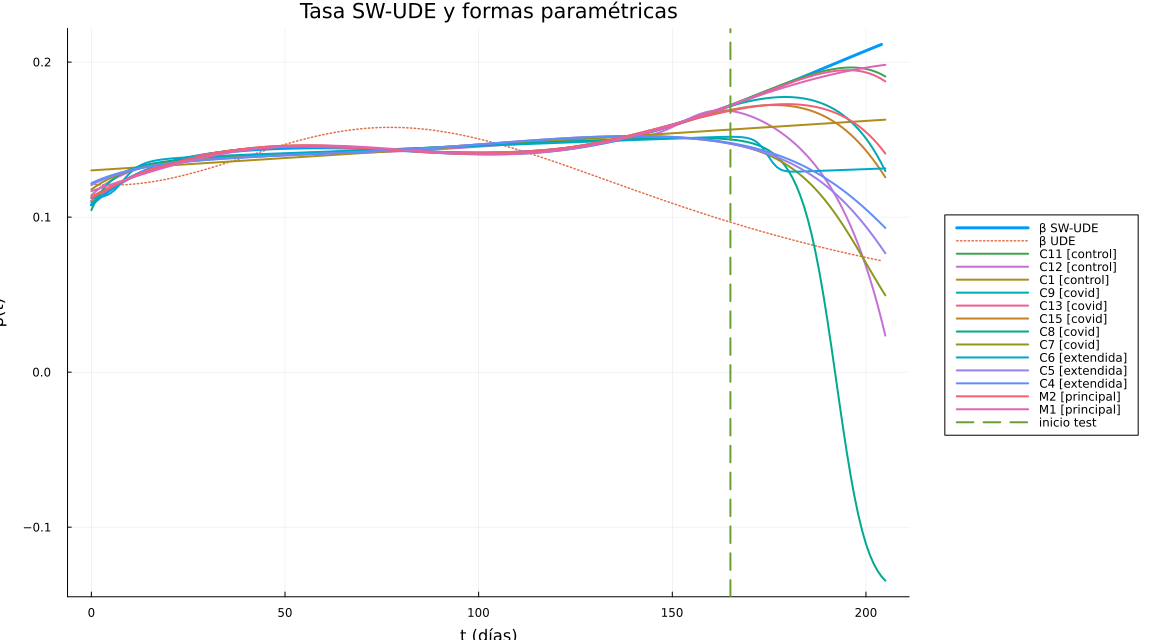

In [12]:
display(p_beta)


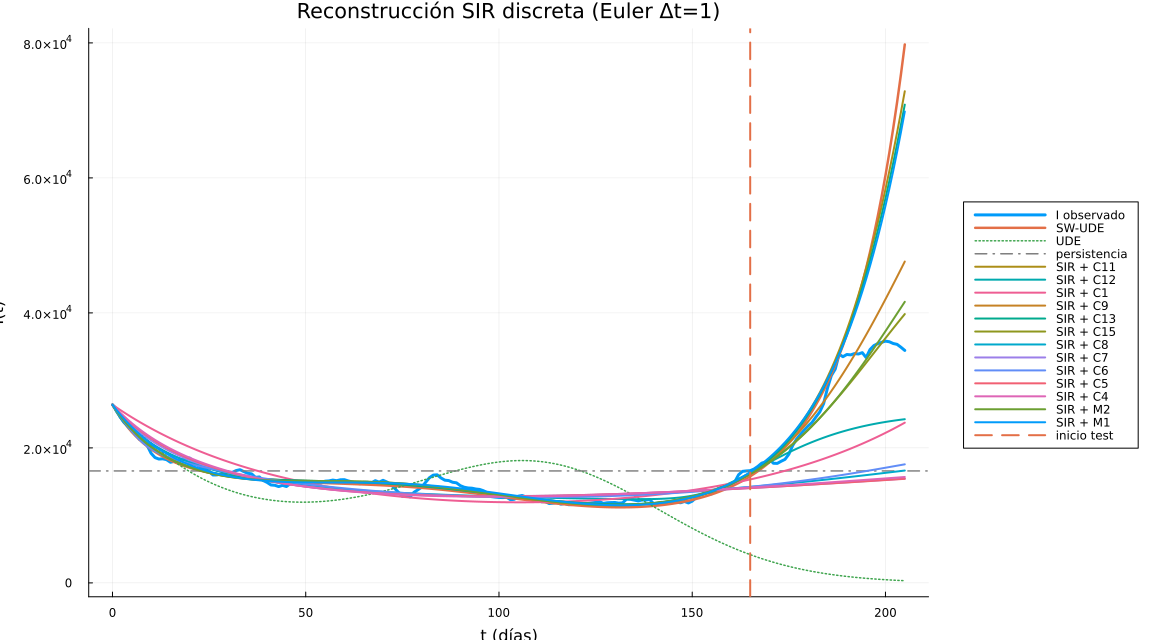

In [13]:
display(p_I)


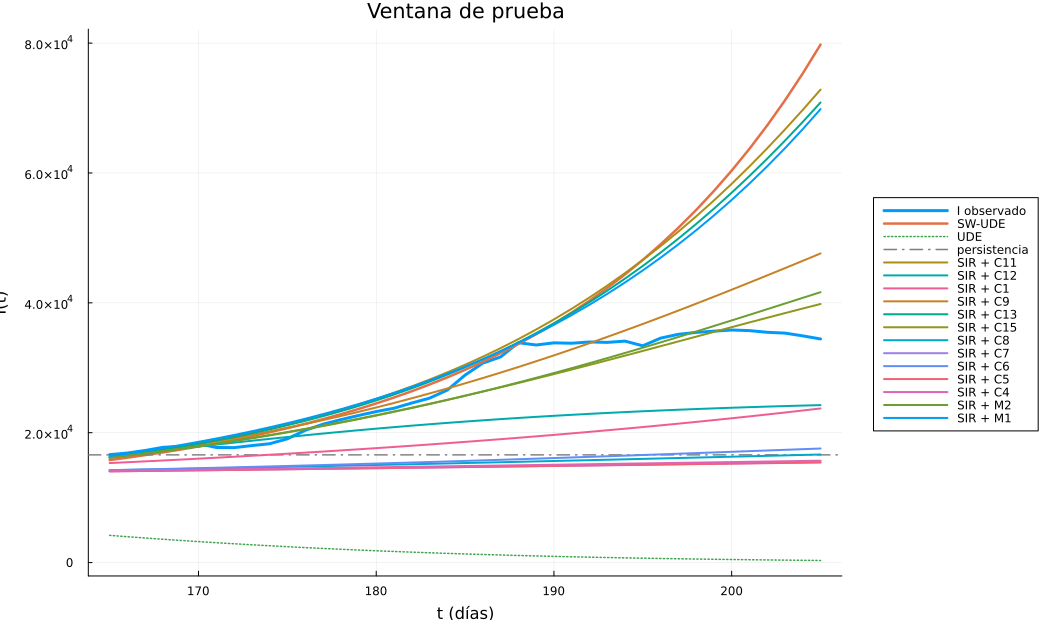

In [14]:
display(p_I_test)


## 12. Archivos generados


In [15]:
println("EXP_DIR = ", EXP_DIR)
println()

for f in sort(readdir(EXP_DIR))
    println(" - ", f)
end


EXP_DIR = /home/tesis/codigos/SW_UDE/notebook/regresion_variantes_v5_1_corregido/destilacion_parametrica_v5_1_covid

 - I_familias.png
 - I_test.png
 - beta_familias.png
 - comparacion_I.csv
 - multistart_algebraico_C1.csv
 - multistart_algebraico_C11.csv
 - multistart_algebraico_C12.csv
 - multistart_algebraico_C13.csv
 - multistart_algebraico_C15.csv
 - multistart_algebraico_C4.csv
 - multistart_algebraico_C5.csv
 - multistart_algebraico_C6.csv
 - multistart_algebraico_C7.csv
 - multistart_algebraico_C8.csv
 - multistart_algebraico_C9.csv
 - multistart_algebraico_M1.csv
 - multistart_algebraico_M2.csv
 - refinamiento_dinamico_C1.csv
 - refinamiento_dinamico_C11.csv
 - refinamiento_dinamico_C12.csv
 - refinamiento_dinamico_C13.csv
 - refinamiento_dinamico_C15.csv
 - refinamiento_dinamico_C4.csv
 - refinamiento_dinamico_C5.csv
 - refinamiento_dinamico_C6.csv
 - refinamiento_dinamico_C7.csv
 - refinamiento_dinamico_C8.csv
 - refinamiento_dinamico_C9.csv
 - refinamiento_dinamico_M1.csv
 